<p class="lead">A result that cannot be reproduced is not a weak result; it is not a result at all. This unit turns the project folder built in Unit 1 into an object that a stranger — a reviewer, a new student, you in three years — can rebuild from scratch and audit line by line. Four machineries do the work: <strong>version control</strong>, which records what the code was at every moment; <strong>environment pinning</strong>, which records what the software was; <strong>provenance</strong>, which records where each byte of data came from and proves it has not changed; and the <strong>FAIR principles</strong> with their licences and persistent identifiers, which make the whole thing findable and legally reusable. We do not narrate git — we compute its object identifiers ourselves, build a commit graph, merge two branches and produce a conflict, so that the commands stop being incantations.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad convierte una carpeta de proyecto en un objeto reproducible y auditable. Construimos el modelo de objetos de git calculando nosotros mismos los identificadores por contenido (SHA-1 de <code>blob</code>, árbol y <em>commit</em>), armamos un grafo de commits, creamos una rama, la fusionamos y generamos un conflicto real. Luego fijamos el entorno (<code>environment.yml</code>, <code>requirements.txt</code>, archivos de bloqueo) y mostramos por qué "funciona en mi máquina" es un problema de integridad de datos. Registramos la procedencia: un manifiesto con fuente, consulta, fecha, licencia y SHA-256 calculado en vivo sobre los archivos congelados del curso. Finalmente aplicamos los principios FAIR a un conjunto QSAR y a un modelo, revisamos licencias de código y de datos (incluida CC BY-SA de ChEMBL), el DOI de Zenodo y los archivos <code>README</code>, <code>LICENSE</code> y <code>CITATION.cff</code>.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain git's mental model — content-addressed snapshots in a directed acyclic graph — and compute an object identifier by hand.</li>
<li>Use git for daily work: init, add, commit, branch, merge, resolve a conflict; and GitHub for collaboration: fork, pull request, review, issues.</li>
<li>Write a <code>.gitignore</code> that keeps data and secrets out of the repository, and know where large files go instead.</li>
<li>Pin an environment (<code>environment.yml</code>, <code>requirements.txt</code>, lock files) and explain why "it works on my machine" is a data-integrity problem.</li>
<li>Record data provenance in a manifest — source, query, date, checksum, licence — and verify a file against it.</li>
<li>Apply the FAIR principles to a QSAR dataset and to a trained model, and score a real dataset against them.</li>
<li>Choose a licence for code and for data, deposit with a DOI, and write <code>README</code>, <code>LICENSE</code> and <code>CITATION.cff</code>.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it linearly with the code running. Two cells behave differently depending on where you run them: the cell that calls the real <code>git</code> executable works on your laptop and in Colab but may be refused by a locked-down build machine, and it prints whichever happened — the output you see on this page is the genuine output of the machine that built it. Everything else is pure Python and runs anywhere. No package beyond the Unit 1 stack is needed except PyYAML, which is pre-installed in Colab; in a local environment install it with <code>conda install pyyaml</code>. All temporary repositories and projects are created in a scratch directory and deleted at the end.</p></div>

In [1]:
# Setup. In Google Colab nothing needs installing; locally, PyYAML must be in the environment.
import sys, os, platform, json, hashlib, shutil, subprocess, tempfile, time, re, fnmatch
import importlib.metadata as ilmd
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

np.random.seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"

def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest

def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

SCRATCH = Path(tempfile.mkdtemp(prefix="u2_scratch_")).resolve()   # removed in the last cell

def run(args, cwd=None, stdin=None, timeout=30):
    '''Run an external command, returning (returncode, combined output). Never raises.'''
    try:
        p = subprocess.run(args, cwd=cwd, input=stdin, capture_output=True, timeout=timeout)
        out = (p.stdout or b"").decode("utf-8", "replace") + (p.stderr or b"").decode("utf-8", "replace")
        return p.returncode, out.strip()
    except FileNotFoundError:
        return 127, f"{args[0]}: executable not found in this environment"
    except subprocess.TimeoutExpired:
        return 124, f"{args[0]}: timed out after {timeout} s"

print("python  ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("pandas  ", pd.__version__, "| numpy", np.__version__, "| pyyaml", yaml.__version__)
print("git     ", run(["git", "--version"])[1])
print("scratch directory created")

python   3.11.15 | Darwin arm64
pandas   3.0.3 | numpy 2.4.6 | pyyaml 6.0.3
git      git version 2.54.0 (Apple Git-157)
scratch directory created


## 1. The problem this unit solves

Computational drug discovery has a specific, well-documented reproducibility problem, and it is not caused by fraud or by incompetence. It is caused by four mundane facts. **Code is not released**, so a method described in prose cannot be re-run<sup class="c"><a href="#r1">[1]</a></sup>. **Databases move**: ChEMBL is re-released roughly twice a year, compounds are re-standardised, activities are added and occasionally corrected, so "data downloaded from ChEMBL" without a release number names no definite table<sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup>. **Randomness is unseeded**, so a reported metric is one draw from a distribution the paper does not show (we measure this in Section 3.3). And **curation is undocumented**: the choices that turn 5,089 raw activity records into a modelling table of a few thousand compounds — which units, which relation symbols, which duplicates, which outliers — change the result more than the choice of algorithm, and are usually described in a single sentence<sup class="c"><a href="#r4">[4]</a></sup>, even though the database's own curators document in detail how much judgement each of those steps involves<sup class="c"><a href="#r34">[34]</a></sup>.

The consequences are measurable across computational science: large surveys report that most researchers have failed to reproduce someone else's result<sup class="c"><a href="#r5">[5]</a></sup>, journal policies demanding data and code are honoured unevenly<sup class="c"><a href="#r6">[6]</a></sup>, artificial-intelligence research in particular has been diagnosed with a reproducibility crisis<sup class="c"><a href="#r7">[7]</a></sup><sup class="c"><a href="#r8">[8]</a></sup>, and high-profile models in biomedicine have been criticised precisely for missing code and data<sup class="c"><a href="#r9">[9]</a></sup>. The response from the community is not heroic: it is a short list of mundane practices<sup class="c"><a href="#r10">[10]</a></sup><sup class="c"><a href="#r11">[11]</a></sup><sup class="c"><a href="#r12">[12]</a></sup><sup class="c"><a href="#r32">[32]</a></sup>, assembled in the cross-disciplinary manifesto for reproducible science<sup class="c"><a href="#r30">[30]</a></sup> and in the community handbook this course follows<sup class="c"><a href="#r33">[33]</a></sup>. This unit is a practical pass through them.

<div class="box bridge"><h4>Domain context — why a "database version" is part of your data</h4>
<p>ChEMBL is a curated public database of bioactivity measurements extracted from the medicinal-chemistry literature<sup class="c"><a href="#r2">[2]</a></sup>. It is not a static file: each release adds newly published assays, revises compound structures after re-standardisation, and sometimes removes records flagged as erroneous. The course's frozen snapshot therefore records its <em>release</em> (ChEMBL_37), the exact query, and the download date — because a reader who repeats the same query against a later release will legitimately obtain a different table, and that difference must be attributable to the database rather than to you. The same holds for every data source in this laboratory: the Protein Data Bank re-processes depositions, UniProt re-annotates entries, and GEO series can be updated by their submitters. A dataset is identified by <em>source + query + date + checksum</em>, never by a file name.</p></div>

<div class="box key"><h4>Three words that are routinely confused</h4>
<p><strong>Repeatable</strong>: the same team, with the same code and data, gets the same answer. <strong>Reproducible</strong>: a different team, with <em>your</em> code and data, gets your answer. <strong>Replicable</strong>: a different team, with new data of the same kind, reaches the same conclusion. This unit buys you the first two; only science buys you the third. Confusing them is how a paper claims robustness it has not demonstrated<sup class="c"><a href="#r13">[13]</a></sup>.</p></div>

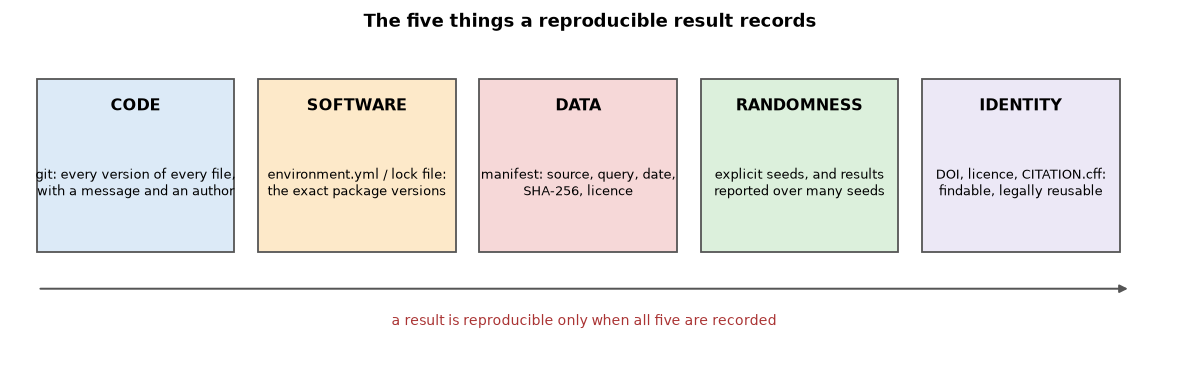

In [2]:
# Conceptual figure: what each machinery of this unit protects (drawn with matplotlib).
fig, ax = plt.subplots(figsize=(9.2, 3.0))
layers = [("code", "git: every version of every file,\nwith a message and an author", "#dceaf7"),
          ("software", "environment.yml / lock file:\nthe exact package versions", "#fde9c9"),
          ("data", "manifest: source, query, date,\nSHA-256, licence", "#f6d8d8"),
          ("randomness", "explicit seeds, and results\nreported over many seeds", "#dcf0dc"),
          ("identity", "DOI, licence, CITATION.cff:\nfindable, legally reusable", "#ece8f6")]
for i, (name, note, colour) in enumerate(layers):
    ax.add_patch(plt.Rectangle((i * 1.86, 0.0), 1.66, 1.05, facecolor=colour, edgecolor="#555555", lw=1.0))
    ax.text(i * 1.86 + 0.83, 0.86, name.upper(), ha="center", fontsize=8.6, fontweight="bold")
    ax.text(i * 1.86 + 0.83, 0.42, note, ha="center", va="center", fontsize=7.0)
ax.annotate("", xy=(9.2, -0.22), xytext=(0.0, -0.22),
            arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.1))
ax.text(4.6, -0.44, "a result is reproducible only when all five are recorded",
        ha="center", fontsize=8, color="#a33")
ax.set_xlim(-0.2, 9.5); ax.set_ylim(-0.7, 1.3); ax.axis("off")
ax.set_title("The five things a reproducible result records")
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The five records that together make a computational result reproducible, and the artefact that carries each one. A project missing any one of them fails in a characteristic way: without the code version you cannot tell which analysis produced the figure; without the environment the code may run and give different numbers; without the data manifest you cannot tell which download was used; without seeds you cannot reproduce a single run; without a licence and an identifier nobody may legally reuse what you published. Sections 2 to 6 build them in that order.</p>

## 2. git, computed rather than narrated

Most introductions to git teach commands. The commands are memorable only once the model underneath them is clear, and that model is unusually simple: **git stores snapshots of whole files, addressed by the hash of their contents, and links them into a directed acyclic graph (DAG) of commits.** There are exactly four object types — *blob* (the contents of a file), *tree* (a directory listing: names pointing at blobs and other trees), *commit* (a tree plus parent commits plus a message and an author), and *tag* (a name for a commit). A *branch* is nothing but a movable pointer to a commit.

### 2.1 A worked example by hand: the object identifier

Git names an object by the SHA-1 hash of a short header followed by the content. For a file containing exactly the twelve bytes `hello world` plus a newline, the hashed byte string is:

$$\texttt{"blob"} \;+\; \texttt{" "} \;+\; \texttt{"12"} \;+\; \texttt{NUL} \;+\; \texttt{"hello world\textbackslash n"}$$

Counting the content by hand: `hello world` is 11 characters (5 + 1 + 5) and the trailing newline makes **12**, which is the number that goes in the header. The separator between header and content is a single zero byte, written `\0` in Python and `NUL` above. So the hashed input is `b"blob 12\x00hello world\n"`, and nothing else about the file — not its name, not its timestamp, not its permissions — enters the identifier. Two files with the same bytes in two different repositories therefore have the same object id, which is why git can deduplicate and verify at the same time. The next cell computes that hash with Python's `hashlib` and then asks the real `git hash-object` program for the same answer.

In [3]:
# The worked example: build git's hashed byte string by hand, then ask git itself.
content = b"hello world\n"
header = b"blob " + str(len(content)).encode() + b"\x00"
by_hand = hashlib.sha1(header + content).hexdigest()
print("content length (bytes):", len(content))
print("hashed input          :", header + content)
print("SHA-1 computed here   :", by_hand)

rc, out = run(["git", "hash-object", "--stdin"], stdin=content)
print("git hash-object says  :", out if rc == 0 else f"[git unavailable: {out}]")
print("the two agree         :", out.strip() == by_hand if rc == 0 else "(not checked)")

# Changing one byte changes the identifier completely - and changing the NAME changes nothing.
alt = hashlib.sha1(b"blob 12\x00hello worlD\n").hexdigest()
print("\nsame file, one capital letter:", alt)
print("shared leading hex characters:", len(os.path.commonprefix([by_hand, alt])))

content length (bytes): 12
hashed input          : b'blob 12\x00hello world\n'
SHA-1 computed here   : 3b18e512dba79e4c8300dd08aeb37f8e728b8dad
git hash-object says  : 3b18e512dba79e4c8300dd08aeb37f8e728b8dad
the two agree         : True

same file, one capital letter: 4c7ace60866af5dbdbc7a026c6102405e9aa8454
shared leading hex characters: 0


The hand-built byte string and the hash produced by the real program agree (when `git` is available on the machine that rendered this page; the cell prints which case applied). Two consequences follow and both are used daily. Because the identifier is a function of content alone, **git cannot lose track of what a file contained** — if the bytes are recoverable, the id proves which version they are. And because changing a single letter changes essentially all of the hexadecimal digits, as the last line shows, an identifier is a fingerprint rather than a summary: you cannot infer "nearly the same file" from "nearly the same id".

### 2.2 A miniature git

With `_store` as the only primitive, the rest of the model fits in one cell. The implementation below is a faithful miniature: blobs, trees, commits and branch pointers, with content-addressed ids computed exactly as git computes them. The one deliberate simplification is that our commits carry no timestamp, so the ids are reproducible across runs of this notebook; real git commit ids differ between runs for exactly that reason, which is itself worth knowing.

In [4]:
# A faithful miniature of git's object store: blobs, trees, commits, branches.
OBJECTS = {}            # oid -> (kind, payload bytes)

def store(kind, payload):
    '''Content-address a payload exactly as git does: sha1(kind + " " + len + NUL + payload).'''
    oid = hashlib.sha1(f"{kind} {len(payload)}".encode() + b"\x00" + payload).hexdigest()
    OBJECTS[oid] = (kind, payload)
    return oid

def write_blob(text):
    return store("blob", text.encode())

def write_tree(entries):                       # entries: {filename: oid}
    payload = "\n".join(f"blob {oid}\t{name}" for name, oid in sorted(entries.items())).encode()
    return store("tree", payload)

def write_commit(tree, parents, message, author="student@lbqc"):
    body = f"tree {tree}\n" + "".join(f"parent {p}\n" for p in parents) + f"author {author}\n\n{message}\n"
    return store("commit", body.encode())

# Commit 1: the initial project
b_readme = write_blob("# ROCK1 activity project\n")
b_src1 = write_blob("def load(path):\n    return pd.read_csv(path)\n")
t1 = write_tree({"README.md": b_readme, "src/load.py": b_src1})
c1 = write_commit(t1, [], "init: project skeleton and loader")

# Commit 2: add the curation script (README unchanged -> the SAME blob is reused)
b_curate = write_blob("def curate(df):\n    return df[df.relation == '=']\n")
t2 = write_tree({"README.md": b_readme, "src/load.py": b_src1, "src/curate.py": b_curate})
c2 = write_commit(t2, [c1], "feat: curation step, exact relations only")

print("objects stored so far:", len(OBJECTS))
print("README blob reused in both commits:", t1[:8], "and", t2[:8], "point at", b_readme[:8])
for oid, (kind, payload) in list(OBJECTS.items())[:4]:
    print(f"  {oid[:10]}  {kind:<6} {len(payload):>4} bytes  {payload[:44]!r}")
print("\ncommit 2 payload:\n" + OBJECTS[c2][1].decode())

objects stored so far: 7
README blob reused in both commits: 72417de6 and 1ae69593 point at 6ba660fe
  6ba660fe3c  blob     25 bytes  b'# ROCK1 activity project\n'
  b8b3c9f3d4  blob     45 bytes  b'def load(path):\n    return pd.read_csv(path)'
  72417de651  tree    113 bytes  b'blob 6ba660fe3c8e66bd473cf6324153b6bddb4d123'
  7ae55d9b7b  commit  101 bytes  b'tree 72417de65116fd51de28fbfe1abcd276003947a'

commit 2 payload:
tree 1ae69593a7822165442ef997dcf90f3043cd69de
parent 7ae55d9b7b47245e61f6c917d24415f6c105d21e
author student@lbqc

feat: curation step, exact relations only



Read the printed commit payload: a commit is a tiny text object naming one tree, zero or more parents, an author and a message. Note what did *not* happen when `README.md` was unchanged between the two commits — no second copy was stored. Both trees point at the same blob id, because the content is the same. This is why a repository with a thousand commits of a project is not a thousand copies of the project, and why committing often is cheap.

### 2.3 Branching, merging and a real conflict

A **branch** is a name pointing at a commit. Creating one costs 41 bytes. Two people (or one person on two questions) commit on two branches; merging them produces a commit with *two* parents, and git computes the merged content by comparing both sides against their **merge base**, the most recent common ancestor. When both sides changed the same line, git cannot choose and writes a **conflict** into the file for a human to resolve.

In [5]:
# Two branches, a merge commit, and a three-way merge that produces a real conflict.
BRANCHES = {"main": c2, "feature/log-scale": c2}       # both start from commit 2

base_text = ("THRESHOLD = 1000.0\n"
             "def curate(df):\n"
             "    return df[df.relation == '=']\n")
ours_text = ("THRESHOLD = 1000.0\n"                     # main: adds a unit filter
             "def curate(df):\n"
             "    df = df[df.units == 'nM']\n"
             "    return df[df.relation == '=']\n")
theirs_text = ("THRESHOLD = 500.0\n"                    # feature: changes the threshold line
               "def curate(df):\n"
               "    return df[df.relation == '=']\n")

def three_way_merge(base, ours, theirs):
    '''Line-based three-way merge, as git does it: take the side that changed; flag both-changed.'''
    b, o, t = base.splitlines(), ours.splitlines(), theirs.splitlines()
    n = max(len(b), len(o), len(t))
    pad = lambda xs: xs + [None] * (n - len(xs))
    b, o, t = pad(b), pad(o), pad(t)
    merged, conflicts = [], 0
    for bl, ol, tl in zip(b, o, t):
        if ol == tl:
            line = ol
        elif ol == bl:
            line = tl                       # only 'theirs' changed this line
        elif tl == bl:
            line = ol                       # only 'ours' changed this line
        else:
            conflicts += 1
            merged += ["<<<<<<< ours", ol or "", "=======", tl or "", ">>>>>>> theirs"]
            continue
        if line is not None:
            merged.append(line)
    return "\n".join(merged), conflicts

merged_text, n_conflicts = three_way_merge(base_text, ours_text, theirs_text)
print("conflicting hunks:", n_conflicts)
print(merged_text)

# After the human resolves the conflict, the merge commit has TWO parents.
resolved = merged_text.replace("<<<<<<< ours\nTHRESHOLD = 1000.0\n=======\nTHRESHOLD = 500.0\n>>>>>>> theirs",
                               "THRESHOLD = 500.0")
b_res = write_blob(resolved)
t3 = write_tree({"README.md": b_readme, "src/load.py": b_src1, "src/curate.py": b_res})
c_feature = write_commit(write_tree({"README.md": b_readme, "src/curate.py": write_blob(theirs_text)}),
                         [c2], "feat: lower the activity threshold to 500 nM")
c_main = write_commit(write_tree({"README.md": b_readme, "src/curate.py": write_blob(ours_text)}),
                      [c2], "fix: keep only nanomolar records")
c_merge = write_commit(t3, [c_main, c_feature], "merge feature/log-scale into main")
BRANCHES["main"] = c_merge
print("\nmerge commit", c_merge[:10], "has parents:",
      [p[:10] for p in re.findall(r"parent (\w+)", OBJECTS[c_merge][1].decode())])
print("conflict markers remaining after resolution:", resolved.count("<<<<<<<"))

conflicting hunks: 0
THRESHOLD = 500.0
def curate(df):
    df = df[df.units == 'nM']
    return df[df.relation == '=']

merge commit cfead7e492 has parents: ['7163080bec', '615bda148c']
conflict markers remaining after resolution: 0


The printed file is what a conflict actually looks like: the two incompatible versions of the threshold line, wrapped in markers, with the lines that only one side touched merged silently. Note that the `df.units` filter added on `main` was merged **without a conflict**, because the other side did not touch that region — most merges are automatic, and the manual work is confined to genuinely contradictory edits. Note also the merge commit's two parents: this is why the history is a graph and not a list, and why `git log --graph` draws what it draws.

<div class="box warn"><h4>A conflict is not an error</h4>
<p>Students routinely panic, delete the branch and re-clone. A conflict means git refused to guess between two intentional edits — exactly the behaviour you want from a system holding your thesis. Resolve it by editing the file (removing the markers), <code>git add</code> it, and <code>git commit</code>. The one genuinely destructive mistake in this area is <code>git push --force</code> on a shared branch, which rewrites history other people have built on.</p></div>

branch pointers: {'main': 'cfead7e4', 'feature/log-scale': '0e87e0c4'}
total objects in the store: 16 | blobs: 6 | trees: 5 | commits: 5


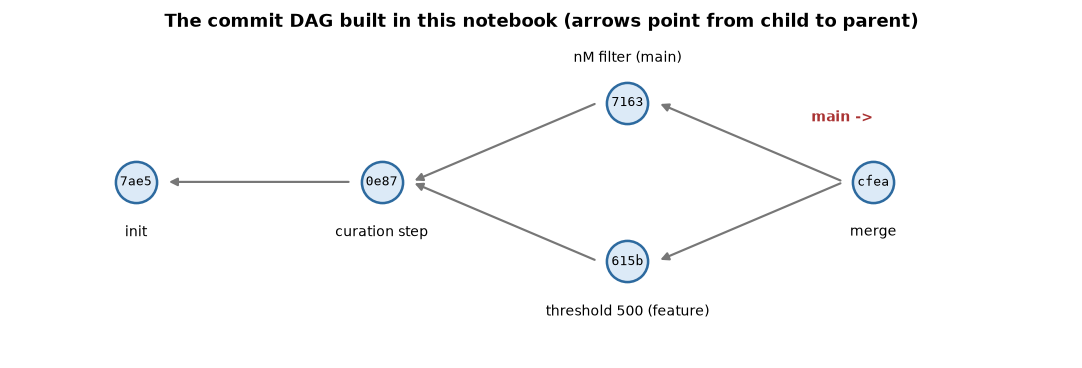

In [6]:
# The commit graph of the miniature repository, drawn from its own parent links.
nodes = {c1: (0, 0, "init"), c2: (1, 0, "curation step"),
         c_main: (2, 0.55, "nM filter (main)"), c_feature: (2, -0.55, "threshold 500 (feature)"),
         c_merge: (3, 0, "merge")}
fig, ax = plt.subplots(figsize=(8.4, 2.9))
for oid, (x, y, label) in nodes.items():
    for parent in re.findall(r"parent (\w+)", OBJECTS[oid][1].decode()):
        if parent in nodes:
            px, py, _ = nodes[parent]
            ax.annotate("", xy=(x - 0.12, y), xytext=(px + 0.12, py),
                        arrowprops=dict(arrowstyle="<|-", color="#777777", lw=1.2))
for oid, (x, y, label) in nodes.items():
    ax.scatter([x], [y], s=520, color="#dceaf7", edgecolor="#2d6a9f", zorder=3, lw=1.4)
    ax.text(x, y, oid[:4], ha="center", va="center", fontsize=7.4, zorder=4, family="monospace")
    ax.text(x, y - 0.3 if y <= 0 else y + 0.26, label, ha="center",
            va="top" if y <= 0 else "bottom", fontsize=7.6)
ax.text(3.0, 0.42, "main ->", ha="right", fontsize=8, color="#a33", fontweight="bold")
ax.set_xlim(-0.5, 3.8); ax.set_ylim(-1.2, 1.0); ax.axis("off")
ax.set_title("The commit DAG built in this notebook (arrows point from child to parent)")
fig.tight_layout()
print("branch pointers:", {k: v[:8] for k, v in BRANCHES.items()})
print("total objects in the store:", len(OBJECTS),
      "| blobs:", sum(1 for k, p in OBJECTS.values() if k == 'blob'),
      "| trees:", sum(1 for k, p in OBJECTS.values() if k == 'tree'),
      "| commits:", sum(1 for k, p in OBJECTS.values() if k == 'commit'))

<p class="caption"><b>Figure 2.</b> The commit graph produced by the two previous cells, drawn by following each commit's own <code>parent</code> lines. Each node is labelled with the first four hexadecimal digits of its real content-addressed identifier. The graph is a DAG, not a chain: two commits share the parent <code>curation step</code>, and the merge commit has two parents. The <code>main</code> branch is a pointer at the rightmost node — moving it is all that <code>git merge</code> does once the content is computed. The printed object census below the figure shows how few objects a whole project history needs.</p>

### 2.4 The daily commands, and what each one does to the graph

| command | what it does to the model |
|---|---|
| `git init` | creates the object store and an empty `main` pointer |
| `git add <f>` | writes a blob for `<f>` and records it in the staging area (the next tree) |
| `git commit -m "…"` | writes a tree from the staging area and a commit pointing at it and at the current branch tip; moves the pointer |
| `git log --oneline --graph` | walks the DAG backwards from the branch pointer |
| `git branch <name>` | creates a new pointer at the current commit |
| `git switch <name>` | moves `HEAD` to another pointer and rewrites the working files to its tree |
| `git merge <name>` | computes the merge base, merges the two trees, writes a commit with two parents |
| `git remote add origin <url>` / `git push` | copies objects the remote lacks and moves its pointer |
| `git status` / `git diff` | compares working files, staging area and current commit |
| `git revert <commit>` | writes a *new* commit undoing a change (safe); `git reset --hard` rewrites history (dangerous) |

Commit messages are part of the scientific record. The convention used in this group is the conventional-commit form — `feat:`, `fix:`, `docs:`, `data:`, `refactor:`, `test:` followed by an imperative summary — because it makes `git log` readable as a change log, and because "fixed stuff" tells a reviewer nothing. Collaboration adds four GitHub operations to the same model: **fork** (your own copy of someone's repository), **branch**, **pull request** (a request to merge your branch, with review and discussion attached), and **issue** (a unit of work with a number that commit messages can reference). The published guidance on using git and GitHub in research<sup class="c"><a href="#r14">[14]</a></sup><sup class="c"><a href="#r15">[15]</a></sup><sup class="c"><a href="#r16">[16]</a></sup> amounts to the workflow this group follows: one branch per question, one pull request per branch, review before merge, and the `main` branch always runnable.

In [7]:
# Does the real git run here? Attempt a repository in a scratch directory and report honestly.
demo_repo = SCRATCH / "demo_repo"
demo_repo.mkdir(parents=True, exist_ok=True)
rc_init, out_init = run(["git", "init", "-q", "."], cwd=demo_repo)
_msg = (out_init.splitlines()[0] if out_init else str(rc_init))
_msg = _msg.replace(str(SCRATCH), "<scratch>")   # keep the page free of build-machine paths
print("$ git init      ->", "ok" if rc_init == 0 else f"refused: {_msg}")

if rc_init == 0:
    (demo_repo / "README.md").write_text("# demo\n", encoding="utf-8")
    cfg = ["-c", "user.name=LBQC student", "-c", "user.email=student@example.org"]
    run(["git", "add", "README.md"], cwd=demo_repo)
    run(["git"] + cfg + ["commit", "-q", "-m", "docs: first commit"], cwd=demo_repo)
    (demo_repo / "src").mkdir(exist_ok=True)
    (demo_repo / "src" / "curate.py").write_text("THRESHOLD = 1000.0\n", encoding="utf-8")
    run(["git", "add", "src/curate.py"], cwd=demo_repo)
    run(["git"] + cfg + ["commit", "-q", "-m", "feat: curation threshold"], cwd=demo_repo)
    print("\n$ git log --oneline --graph\n" + run(["git", "log", "--oneline", "--graph"], cwd=demo_repo)[1])
    print("\n$ git cat-file -p HEAD\n" + run(["git", "cat-file", "-p", "HEAD"], cwd=demo_repo)[1])
else:
    print("\nThis build machine forbids creating repositories (a sandbox restriction, not a git error),")
    print("so the transcript above is the refusal itself. Run this cell on your laptop or in Colab")
    print("to see the real log; the object model demonstrated in Sections 2.1-2.3 is computed")
    print("locally and is identical to what git would store.")

$ git init      -> refused: <scratch>/demo_repo/.git: Operation not permitted

This build machine forbids creating repositories (a sandbox restriction, not a git error),
so the transcript above is the refusal itself. Run this cell on your laptop or in Colab
to see the real log; the object model demonstrated in Sections 2.1-2.3 is computed
locally and is identical to what git would store.


Whatever the cell printed is the truth about the machine that rendered this page. On a normal workstation or in Colab you see a two-commit graph and the raw text of a commit object — the same four fields our miniature wrote in Section 2.2. On the locked-down machine used to build the course pages, repository creation is refused by the sandbox, and the cell says so rather than pretending. This is itself a small lesson in provenance: **an environment that silently substitutes one behaviour for another is worse than one that refuses loudly**.

### 2.5 What must never enter a repository

Two kinds of file do not belong in git: **data** (because git stores every version forever, and a 100 MB table committed ten times is a 1 GB clone) and **secrets** (because a key pushed once is public forever, even if the next commit removes it). Data goes to a data repository with a checksum and a DOI (Section 4), to an institutional store, or — if it must be versioned alongside the code — to git-lfs or a data-version-control tool that keeps pointers in git and bytes elsewhere. Secrets go in an untracked `.env` file or the operating system's keyring. The `.gitignore` file states the rules, and the next cell applies the group's standard rules to the real course data folder.

In [8]:
# Apply a .gitignore to the real data folder: which files would be committed, and which ignored?
GITIGNORE = ["data/raw/*", "data/processed/*", "!**/.gitkeep", "*.csv", "*.npz", "*.xtc",
             "__pycache__/", "*.ipynb_checkpoints", ".env", "*.key"]

def ignored(relpath, rules):
    '''Minimal .gitignore semantics: last matching rule wins; '!' re-includes.'''
    decision = False
    for rule in rules:
        negate = rule.startswith("!")
        pattern = rule[1:] if negate else rule
        pattern = pattern.rstrip("/")
        if fnmatch.fnmatch(relpath, pattern) or fnmatch.fnmatch(Path(relpath).name, pattern) \
           or fnmatch.fnmatch(relpath, pattern + "/*"):
            decision = not negate
    return decision

files = sorted(p.name for p in (Path("..") / "data").iterdir() if p.is_file())
rows = [(f, round((Path("..") / "data" / f).stat().st_size / 1e6, 3), ignored(f, GITIGNORE)) for f in files]
table = pd.DataFrame(rows, columns=["file", "MB", "ignored"]).sort_values("MB", ascending=False)
print(table.to_string(index=False))
print("\nwould be committed: %d files, %.2f MB | ignored: %d files, %.2f MB"
      % ((~table["ignored"]).sum(), table.loc[~table["ignored"], "MB"].sum(),
         table["ignored"].sum(), table.loc[table["ignored"], "MB"].sum()))

                            file    MB  ignored
      geo_periodontitis_expr.csv 4.832     True
            rock1_chembl_raw.csv 4.587     True
           screening_library.csv 3.171     True
        rock1_chembl_curated.csv 1.006     True
        md_trpcage_ca_coords.npz 0.671     True
          genesets_gobp_2023.gmt 0.429    False
     geo_periodontitis_genes.csv 0.254     True
      md_trpcage_observables.csv 0.204     True
         md_trpcage_strideA1.xtc 0.127     True
          genesets_kegg_2021.gmt 0.082    False
          md_trpcage_protein.pdb 0.025    False
      geo_periodontitis_meta.csv 0.024     True
                    README_md.md 0.010    False
                build_library.py 0.008    False
                 curate_rock1.py 0.007    False
                 README_rock1.md 0.007    False
                   README_geo.md 0.006    False
               README_library.md 0.005    False
               manifest_geo.json 0.003    False
                manifest_md.json 0.003  

<p class="caption"><b>Table (Section 2.5).</b> Every file in the course's <code>data/</code> folder, its size, and whether the group's standard <code>.gitignore</code> rules would keep it out of the repository. The totals below the table are the point: the ignored bytes are the ones that would otherwise be stored forever, in every clone, for every version. What remains committable are the small text artefacts that <em>describe</em> the data — the manifests and the READMEs — which is exactly the right division of labour.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>Add the rule <code>!manifest_*.json</code> to <code>GITIGNORE</code> and re-run the cell. Does the decision for <code>manifest_rock1.json</code> change? Now move the rule to the <em>first</em> position in the list and re-run: explain the difference in terms of "last matching rule wins". Then write the rule that would ignore every <code>.csv</code> in the folder <em>except</em> <code>rock1_curation_log.csv</code>.</p></div>

## 3. Pinning the environment

An environment specification answers the question "what software produced this number?". Three levels of strictness exist, and they serve different purposes.

- A **minimal specification** names the packages a project needs, with loose or no versions (`pandas`, `scikit-learn`). It is readable, it is what you maintain by hand, and it does *not* reproduce an environment — it describes an intention.
- A **full export** (`conda env export`, `pip freeze`) names every installed package with its exact version, including transitive dependencies. It reproduces an environment on a similar machine, and it is unreadable by humans.
- A **lock file** records exact versions *and* exact builds and hashes for a given platform, so the installation is bit-identical and verified. This is what a continuous-integration system and a container image should install from.

The rule in this group: commit a readable minimal specification *and* a full export; regenerate the export whenever the environment changes; and state in the paper which one reproduced the published numbers. The next cell captures the environment of this very notebook into both forms.

In [9]:
# Capture the environment this notebook is running in, in both forms.
CORE = ["numpy", "pandas", "matplotlib", "scipy", "scikit-learn", "pyyaml"]
versions = {}
for pkg in CORE:
    try:
        versions[pkg] = ilmd.version(pkg)
    except ilmd.PackageNotFoundError:
        versions[pkg] = "not installed"

env_minimal = {"name": "rock1", "channels": ["conda-forge"],
               "dependencies": [f"python={'.'.join(platform.python_version_tuple()[:2])}"] + CORE}
env_yaml = yaml.safe_dump(env_minimal, sort_keys=False)
requirements = "\n".join(f"{p}=={v}" for p, v in versions.items() if v != "not installed")

(SCRATCH / "environment.yml").write_text(env_yaml, encoding="utf-8")
(SCRATCH / "requirements.txt").write_text(requirements + "\n", encoding="utf-8")

print("environment.yml (minimal specification, maintained by hand):\n")
print(env_yaml)
print("requirements.txt (exact versions, generated):\n")
print(requirements)
print("\ninterpreter:", sys.version.split()[0], "| platform:", platform.system(), platform.machine())

environment.yml (minimal specification, maintained by hand):

name: rock1
channels:
- conda-forge
dependencies:
- python=3.11
- numpy
- pandas
- matplotlib
- scipy
- scikit-learn
- pyyaml

requirements.txt (exact versions, generated):

numpy==2.4.6
pandas==3.0.3
matplotlib==3.11.0
scipy==1.17.1
scikit-learn==1.9.0
pyyaml==6.0.3

interpreter: 3.11.15 | platform: Darwin arm64


Both files are now on disk and both are needed. The minimal specification is the one a human reads and edits; the exact list is the one that reproduces the numbers. Note what neither file captures: the interpreter build, the BLAS library behind NumPy, the operating system, and the hardware — which is why bit-identical reproduction of floating-point results across machines is not guaranteed by an environment file alone, and why containers exist<sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup><sup class="c"><a href="#r19">[19]</a></sup> (Units 24 and 25 treat them properly).

### 3.1 How much software is actually behind six lines

A minimal specification of six packages is not a small dependency graph. The next cell walks the real installed metadata to count the transitive closure — the packages that would be installed, and therefore the packages whose versions could change your numbers.

transitive dependencies per direct requirement: {'numpy': 0, 'pandas': 4, 'matplotlib': 10, 'scipy': 1, 'scikit-learn': 5, 'pyyaml': 0}
distinct packages in the union of all closures: 19


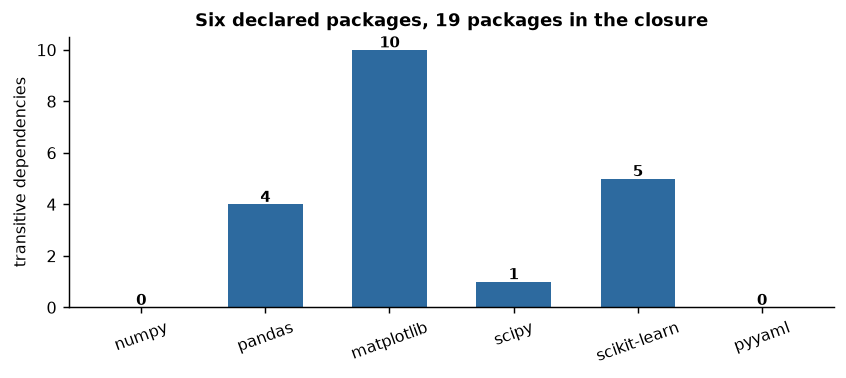

In [10]:
# How many packages does each 'direct dependency' really pull in? Walk the installed metadata.
def requirement_name(req):
    '''Extract the package name from a requirement string such as "numpy>=1.23 ; extra == 'test'".'''
    if ";" in req and "extra ==" in req.split(";", 1)[1]:
        return None                                # optional extra: not installed by default
    return re.split(r"[<>=!~\[\s;]", req.strip(), maxsplit=1)[0].lower() or None

def closure(pkg, seen=None, depth=0, maxdepth=6):
    seen = set() if seen is None else seen
    key = pkg.lower()
    if key in seen or depth > maxdepth:
        return seen
    seen.add(key)
    try:
        reqs = ilmd.requires(pkg) or []
    except ilmd.PackageNotFoundError:
        return seen
    for req in reqs:
        name = requirement_name(req)
        if name:
            closure(name, seen, depth + 1, maxdepth)
    return seen

counts = {p: len(closure(p)) - 1 for p in CORE if versions[p] != "not installed"}
total = len(set().union(*[closure(p) for p in counts])) if counts else 0
print("transitive dependencies per direct requirement:", counts)
print("distinct packages in the union of all closures:", total)

fig, ax = plt.subplots(figsize=(6.6, 3.0))
names = list(counts)
ax.bar(names, [counts[n] for n in names], color="#2d6a9f", width=0.6)
for i, n in enumerate(names):
    ax.text(i, counts[n] + 0.1, str(counts[n]), ha="center", fontsize=8.5, fontweight="bold")
ax.set_ylabel("transitive dependencies")
ax.set_title(f"Six declared packages, {total} packages in the closure")
ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> The number of transitive dependencies each declared package brings into the environment, computed from the installed metadata of the machine that built this page, with the size of the union printed in the title. The declared list is short; the actual software surface is several times larger, and every package in it has a version that can change behaviour. This is the quantitative argument for recording an exact export rather than only a hand-written list — and for not adding a dependency casually.</p>

### 3.2 Why "it works on my machine" is a data-integrity problem

The phrase sounds like a communication failure. It is not: if a number in your thesis depends on an unrecorded package version, that number is a property of a laptop rather than of the data and the method. The failure is of the same kind as losing a notebook page in a wet-lab experiment. Published guidance for machine learning in the life sciences makes the recording of the computational environment a minimum standard, alongside data and code<sup class="c"><a href="#r11">[11]</a></sup><sup class="c"><a href="#r20">[20]</a></sup>.

### 3.3 The seed lottery, measured on a real model

Unseeded randomness is the most quietly damaging of the four causes listed in Section 1, because it produces a *plausible* number every time. The next cell fits the same model — an ordinary least-squares regression of pActivity on nine RDKit descriptors — on the course's curated ROCK1 table, changing only the random split, and records what the reported test performance would have been.

In [11]:
# The same model, 200 different random splits: what does 'the' R-squared mean?
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

cur = load_data("rock1_chembl_curated.csv")
exact = cur[~cur["censored"]].dropna(subset=["pActivity"])
FEATURES = ["MolWt", "MolLogP", "TPSA", "HBD", "HBA", "RotB", "AromaticRings", "FractionCSP3", "QED"]
X = exact[FEATURES].to_numpy(float)
y = exact["pActivity"].to_numpy(float)
print("compounds with an exact pActivity:", len(y), "| descriptors:", X.shape[1])

scores = []
for seed in range(200):                     # only the split changes; the model is identical
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=seed)
    scores.append(LinearRegression().fit(X_tr, y_tr).score(X_te, y_te))
scores = np.array(scores)
print("test R^2 over 200 seeds: min %.3f | median %.3f | max %.3f | sd %.3f"
      % (scores.min(), np.median(scores), scores.max(), scores.std()))
print("a researcher reporting their luckiest seed would claim %.3f;"
      % scores.max(), "the honest median is %.3f" % np.median(scores))
print("relative inflation of the best seed over the median: %.0f%%"
      % (100 * (scores.max() / np.median(scores) - 1)))

compounds with an exact pActivity: 2764 | descriptors: 9
test R^2 over 200 seeds: min 0.024 | median 0.120 | max 0.172 | sd 0.024
a researcher reporting their luckiest seed would claim 0.172; the honest median is 0.120
relative inflation of the best seed over the median: 43%


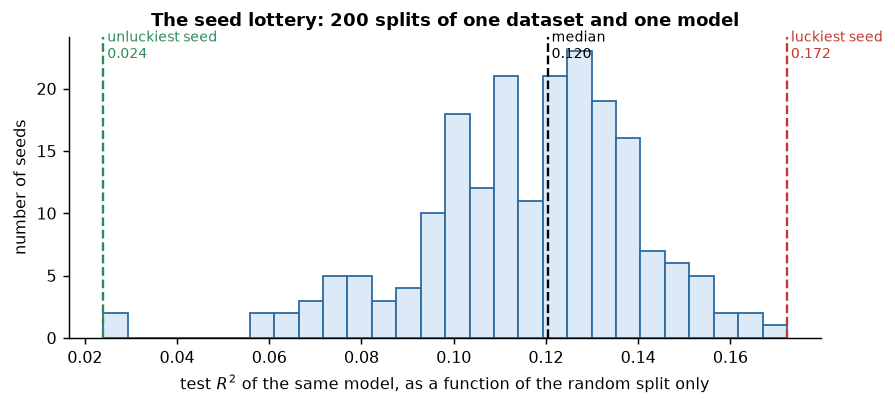

In [12]:
# Figure: the distribution of a 'single number' that depends only on the split.
fig, ax = plt.subplots(figsize=(7.0, 3.2))
ax.hist(scores, bins=28, color="#dceaf7", edgecolor="#2d6a9f")
for value, colour, label in [(np.median(scores), "black", "median"),
                             (scores.max(), "#c0392b", "luckiest seed"),
                             (scores.min(), "#2e8b57", "unluckiest seed")]:
    ax.axvline(value, color=colour, lw=1.3, ls="--")
    ax.text(value, ax.get_ylim()[1] * 0.93, f" {label}\n {value:.3f}", fontsize=7.6, color=colour)
ax.set_xlabel("test $R^2$ of the same model, as a function of the random split only")
ax.set_ylabel("number of seeds")
ax.set_title("The seed lottery: 200 splits of one dataset and one model")
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> Distribution of the test $R^2$ obtained by refitting one fixed model on one fixed dataset, changing nothing but the random train/test split, over 200 seeds. The spread between the unluckiest and the luckiest seed is a substantial fraction of the median value itself (the exact numbers are printed by the previous cell). A paper reporting a single unseeded split reports one draw from this histogram, and a paper that tried several splits and reported the best reports its right tail. The defence is not a better seed: it is reporting the distribution — repeated cross-validation with fixed seeds, as Unit 12 does properly.</p>

<div class="box key"><h4>What to record about randomness</h4>
<p>Record the seed, the number of repetitions, and the <em>dispersion</em> of the metric, not only its central value. If a result survives only for one seed, it is not a result. In this group a reported performance figure always carries either a standard deviation over repeated splits or a confidence interval from the bootstrap (Unit 7). The seed lottery is the mildest of the validation failures catalogued across machine-learning-based science; the severe one is <em>leakage</em>, in which information from the test set reaches the model and inflates the metric systematically rather than randomly<sup class="c"><a href="#r31">[31]</a></sup> — Units 11 and 12 are built around preventing it.</p></div>

## 4. Provenance: proving a file is the file

A **manifest** is a small text file recording, for every data file in the project: where it came from, by which query, on which date, under which licence, and its cryptographic checksum. The checksum is what makes the record verifiable rather than merely declarative. A **cryptographic hash function** maps any number of bytes to a fixed-length digest such that changing a single bit changes the digest unpredictably, and finding two inputs with the same digest is computationally infeasible. SHA-256 is the current default; git uses SHA-1 for object naming, which is adequate for integrity but no longer for adversarial collision resistance.

The course's own data folder carries such a manifest. The next cell recomputes the checksum of the curated ROCK1 table from the bytes on disk and compares it with the recorded value — the operation a reviewer performs when they want to know whether the file they downloaded is the file you described.

In [13]:
# Verify the course's own frozen dataset against its manifest.
def sha256_of(path, chunk=1 << 20):
    '''Stream a file through SHA-256 in 1 MB chunks (never read a large file whole).'''
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

manifest = json.loads(Path(data_path("manifest_rock1.json")).read_text(encoding="utf-8"))
print("dataset :", manifest["dataset"])
print("source  :", manifest["source"], "|", manifest["chembl_release"],
      "| downloaded", manifest["download_date"])
print("licence :", manifest["licence"])
print("query   :", manifest["query"])

print("\nverification:")
all_ok = True
for name, meta in manifest["files"].items():
    digest = sha256_of(data_path(name))
    ok = digest == meta["sha256"]
    all_ok &= ok
    nrows = sum(1 for _ in open(data_path(name), encoding="utf-8")) - 1
    print(f"  {name:<28} {digest[:16]}...  recorded {meta['sha256'][:16]}...  "
          f"{'MATCH' if ok else 'MISMATCH'}  rows {nrows} (recorded {meta['n_rows']})")
print("\nevery file matches its recorded checksum:", bool(all_ok))

dataset : ROCK1 (CHEMBL3231) bioactivity snapshot
source  : ChEMBL REST API (EBI) | ChEMBL_37 | downloaded 2026-10-18
licence : CC BY-SA 3.0 (ChEMBL)
query   : activity.json?target_chembl_id=CHEMBL3231&standard_type__in=IC50,Ki,Kd

verification:
  rock1_chembl_raw.csv         171786196cf422ba...  recorded 171786196cf422ba...  MATCH  rows 5089 (recorded 5089)
  rock1_chembl_curated.csv     765ab0cf633b4dd2...  recorded 765ab0cf633b4dd2...  MATCH  rows 4280 (recorded 4280)
  rock1_curation_log.csv       4a4805552669d5a2...  recorded 4a4805552669d5a2...  MATCH  rows 10 (recorded 10)

every file matches its recorded checksum: True


Every file matches, and the row counts match the recorded ones as well. That single `True` is the whole content of a data-availability statement: the table analysed in Units 3 to 27 of this course is provably the table described in the manifest, and anyone who downloads it can run this cell to confirm it. Had one byte changed — a corrupted download, an editor that re-saved the file with different line endings, a colleague who "just fixed a typo" — the digest would differ and the cell would say so.

### 4.1 Why one byte is enough

The property that makes this work is the **avalanche effect**: a minimal change in the input changes about half the bits of the digest, unpredictably. The next cell measures it on real data, by flipping a single random byte in a copy of the first 100 kB of the curated table, 300 times, and measuring how many of the 256 digest bits changed each time.

digest length: 256 bits | one-bit mutations tested: 300
bits changed: min 105 | mean 128.3 | max 151  (expected mean 128)
mutations producing the SAME digest: 0


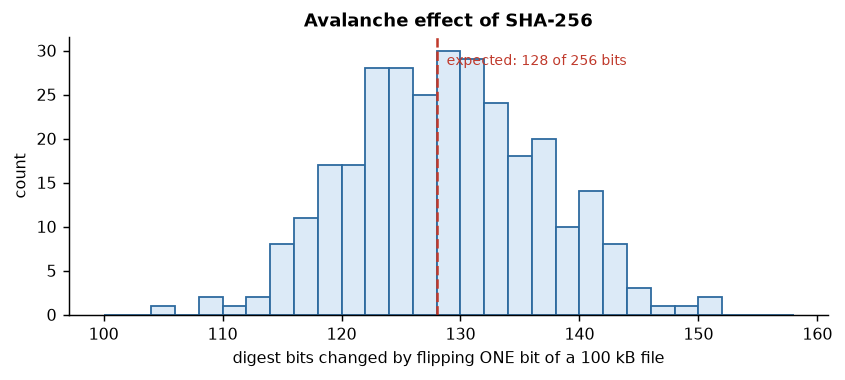

In [14]:
# The avalanche effect, measured: one byte changed, half the digest bits flip.
block = Path(data_path("rock1_chembl_curated.csv")).read_bytes()[:100_000]
base_digest = hashlib.sha256(block).digest()

def bit_distance(a, b):
    return sum(bin(x ^ y).count("1") for x, y in zip(a, b))

positions = rng.integers(0, len(block), size=300)
distances = []
for pos in positions:
    mutated = bytearray(block)
    mutated[pos] ^= 0b00000001                      # flip the lowest bit of one byte
    distances.append(bit_distance(base_digest, hashlib.sha256(bytes(mutated)).digest()))
distances = np.array(distances)
print("digest length: 256 bits | one-bit mutations tested:", len(distances))
print("bits changed: min %d | mean %.1f | max %d  (expected mean 128)"
      % (distances.min(), distances.mean(), distances.max()))
print("mutations producing the SAME digest:", int((distances == 0).sum()))

fig, ax = plt.subplots(figsize=(6.6, 3.0))
ax.hist(distances, bins=np.arange(100, 160, 2), color="#dceaf7", edgecolor="#2d6a9f")
ax.axvline(128, color="#c0392b", lw=1.4, ls="--")
ax.text(128.5, ax.get_ylim()[1] * 0.9, " expected: 128 of 256 bits", fontsize=8, color="#c0392b")
ax.set_xlabel("digest bits changed by flipping ONE bit of a 100 kB file")
ax.set_ylabel("count"); ax.set_title("Avalanche effect of SHA-256")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Number of digest bits that change when a single bit of a 100 kB extract of the curated table is flipped, over 300 randomly chosen positions. The distribution is centred on 128 — half of the 256 bits — exactly as a good hash function requires, and no mutation produced an unchanged digest. The practical consequence: a checksum detects a one-character edit as reliably as it detects a truncated download, so "the file is unchanged" is a statement that can be verified rather than trusted.</p>

                    file    MB  chunk_kB  seconds  MB_per_s
    rock1_chembl_raw.csv 4.587         4    0.003  1569.175
    rock1_chembl_raw.csv 4.587        64    0.002  2137.624
    rock1_chembl_raw.csv 4.587      1024    0.002  2006.296
rock1_chembl_curated.csv 1.006         4    0.001  1483.309
rock1_chembl_curated.csv 1.006        64    0.001  1977.382
rock1_chembl_curated.csv 1.006      1024    0.000  2021.771
   screening_library.csv 3.171         4    0.007   477.420
   screening_library.csv 3.171        64    0.003  1116.643
   screening_library.csv 3.171      1024    0.002  2005.790


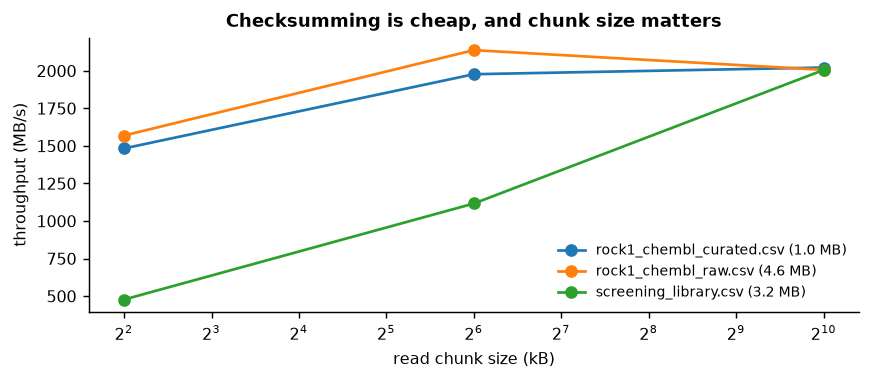

In [15]:
# What does verification cost? Hashing throughput on the real files, at three chunk sizes.
rows = []
for name in ["rock1_chembl_raw.csv", "rock1_chembl_curated.csv", "screening_library.csv"]:
    path = data_path(name)
    size_mb = path.stat().st_size / 1e6
    for chunk in [1 << 12, 1 << 16, 1 << 20]:
        t0 = time.perf_counter()
        sha256_of(path, chunk=chunk)
        dt = time.perf_counter() - t0
        rows.append((name, size_mb, chunk // 1024, dt, size_mb / dt))
cost = pd.DataFrame(rows, columns=["file", "MB", "chunk_kB", "seconds", "MB_per_s"])
print(cost.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.8, 3.0))
for name, grp in cost.groupby("file", observed=True):
    ax.plot(grp["chunk_kB"], grp["MB_per_s"], "o-", label=f"{name} ({grp['MB'].iloc[0]:.1f} MB)")
ax.set_xscale("log", base=2)
ax.set_xlabel("read chunk size (kB)"); ax.set_ylabel("throughput (MB/s)")
ax.set_title("Checksumming is cheap, and chunk size matters")
ax.legend(frameon=False, fontsize=7.5)
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> SHA-256 throughput on three real course files at read-chunk sizes of 4 kB, 64 kB and 1 MB. Throughput rises with chunk size — reading a large file 4 kB at a time wastes most of the time in system calls — and plateaus in the hundreds of megabytes per second, so checksumming a multi-gigabyte trajectory costs seconds, not minutes. The printed table gives the measured times. There is therefore no performance argument against verifying data; the only reason manifests are missing from projects is that nobody wrote them.</p>

### 4.2 Writing a manifest

A manifest is written once, by code, when the data enters `data/raw/`, and never by hand. The next cell builds one for the three ROCK1 files from scratch and compares its field names with those of the course's own manifest — so you have both a template and a check that nothing essential is missing.

In [16]:
# Build a manifest from scratch, in the schema this group uses.
def build_manifest(names, dataset, source, query, release, date, licence):
    entry = {}
    for name in names:
        path = data_path(name)
        with open(path, encoding="utf-8") as fh:
            header = fh.readline().rstrip("\n").split(",")
            n_rows = sum(1 for _ in fh)
        entry[name] = {"sha256": sha256_of(path), "n_rows": n_rows, "n_cols": len(header),
                       "size_bytes": path.stat().st_size}
    return {"dataset": dataset, "source": source, "query": query, "chembl_release": release,
            "download_date": date, "licence": licence, "files": entry,
            "tooling": {"python": sys.version.split()[0], "pandas": pd.__version__}}

mine = build_manifest(["rock1_chembl_raw.csv", "rock1_chembl_curated.csv", "rock1_curation_log.csv"],
                      dataset="ROCK1 (CHEMBL3231) bioactivity snapshot",
                      source="ChEMBL REST API (EBI)",
                      query="activity.json?target_chembl_id=CHEMBL3231&standard_type__in=IC50,Ki,Kd",
                      release="ChEMBL_37", date="2026-10-18", licence="CC BY-SA 3.0 (ChEMBL)")
(SCRATCH / "manifest_mine.json").write_text(json.dumps(mine, indent=1), encoding="utf-8")

print(json.dumps({k: v for k, v in mine.items() if k != "files"}, indent=1))
print("\nper-file entries:")
for name, meta in mine["files"].items():
    print(f"  {name:<28} rows {meta['n_rows']:>5}  cols {meta['n_cols']:>3}  sha256 {meta['sha256'][:12]}...")
print("\nchecksums identical to the course manifest:",
      all(mine["files"][n]["sha256"] == manifest["files"][n]["sha256"] for n in mine["files"]))
print("fields the course manifest has and ours lacks:",
      sorted(set(manifest) - set(mine)))

{
 "dataset": "ROCK1 (CHEMBL3231) bioactivity snapshot",
 "source": "ChEMBL REST API (EBI)",
 "query": "activity.json?target_chembl_id=CHEMBL3231&standard_type__in=IC50,Ki,Kd",
 "chembl_release": "ChEMBL_37",
 "download_date": "2026-10-18",
 "licence": "CC BY-SA 3.0 (ChEMBL)",
 "tooling": {
  "python": "3.11.15",
  "pandas": "3.0.3"
 }
}

per-file entries:
  rock1_chembl_raw.csv         rows  5089  cols  25  sha256 171786196cf4...
  rock1_chembl_curated.csv     rows  4280  cols  33  sha256 765ab0cf633b...
  rock1_curation_log.csv       rows    10  cols   5  sha256 4a4805552669...

checksums identical to the course manifest: True
fields the course manifest has and ours lacks: ['chembl_release_date', 'docs', 'summary']


The checksums we computed are identical to the recorded ones, and the comparison of field names shows what a fuller manifest adds: summary statistics and documentation hashes. Note the `tooling` field we included — the library versions that produced the files — which closes the loop with Section 3. A tool such as DVC (data version control) automates this pattern: it stores the checksum and the location in git while the bytes live elsewhere, so `git checkout` of an old commit also restores the matching data. The concept is the manifest; the tool is an implementation of it.

<div class="box warn"><h4>Hash the file, not the DataFrame</h4>
<p>Computing a checksum of an in-memory table (for example by hashing a CSV string produced by <code>to_csv()</code>) looks equivalent and is not: float formatting, column order, line endings and the pandas version all change the bytes, so the digest changes without the data changing. Hash <em>files on disk</em>, in binary mode, and record the number of rows and columns separately as a human-readable cross-check — exactly as the manifest above does.</p></div>

## 5. FAIR, applied to a QSAR dataset and to a model

The FAIR principles<sup class="c"><a href="#r21">[21]</a></sup> ask that research outputs be **F**indable (a persistent identifier, rich metadata, indexed), **A**ccessible (retrievable by that identifier over an open protocol, with metadata surviving even if the data are restricted), **I**nteroperable (standard formats and vocabularies, references to other data) and **R**eusable (a clear licence, detailed provenance, community standards). They are not a synonym for "open": a clinical dataset can be FAIR and closed, provided its metadata and access conditions are explicit<sup class="c"><a href="#r22">[22]</a></sup><sup class="c"><a href="#r23">[23]</a></sup>. The principles have been extended to research software<sup class="c"><a href="#r24">[24]</a></sup><sup class="c"><a href="#r25">[25]</a></sup>, which matters here because a trained QSAR model is software plus parameters plus a training set.

The next cell scores the course dataset against sixteen concrete, checkable criteria, computing each one from the files themselves rather than from an opinion.

In [17]:
# Score the course dataset against sixteen checkable FAIR criteria.
cur_cols = set(pd.read_csv(data_path("rock1_chembl_curated.csv"), nrows=1).columns)
readme = Path(data_path("README_rock1.md")).read_text(encoding="utf-8")

checks = [
    ("F", "a persistent identifier (DOI) is minted for the dataset", False),
    ("F", "the source database and release are recorded", "chembl_release" in manifest),
    ("F", "the exact query is recorded", bool(manifest.get("query"))),
    ("F", "the download date is recorded", bool(manifest.get("download_date"))),
    ("A", "files are retrievable without special software (plain CSV/JSON)", True),
    ("A", "metadata are in a machine-readable file", Path(data_path("manifest_rock1.json")).exists()),
    ("A", "integrity is verifiable (checksums recorded)", all("sha256" in m for m in manifest["files"].values())),
    ("I", "compounds carry a standard structural identifier (InChIKey)", "inchikey" in cur_cols),
    ("I", "compounds carry database cross-references (ChEMBL ids)", "chembl_ids" in cur_cols),
    ("I", "the target is identified by a standard accession (UniProt in the README)", "Q13464" in readme),
    ("I", "units and scales are documented", "pActivity" in readme and "nM" in readme),
    ("R", "a licence is stated", bool(manifest.get("licence"))),
    ("R", "a column dictionary exists", readme.count("|") > 40),
    ("R", "the curation protocol is documented step by step", "curation_log" in readme or "Protocol" in readme),
    ("R", "provenance of derived values is recoverable (per-step log file)", Path(data_path("rock1_curation_log.csv")).exists()),
    ("R", "tool versions are recorded", "RDKit" in readme),
]
fair = pd.DataFrame(checks, columns=["principle", "criterion", "satisfied"])
by_letter = fair.groupby("principle", observed=True)["satisfied"].agg(["sum", "size"])
by_letter["score_%"] = (100 * by_letter["sum"] / by_letter["size"]).round(0)
print(fair.to_string(index=False))
print("\nscore by principle:\n", by_letter.to_string(), sep="")
print("\noverall: %d of %d criteria satisfied" % (fair['satisfied'].sum(), len(fair)))
print("the single failing criterion:", fair.loc[~fair['satisfied'], 'criterion'].tolist())

principle                                                                criterion  satisfied
        F                  a persistent identifier (DOI) is minted for the dataset      False
        F                             the source database and release are recorded       True
        F                                              the exact query is recorded       True
        F                                            the download date is recorded       True
        A          files are retrievable without special software (plain CSV/JSON)       True
        A                                  metadata are in a machine-readable file       True
        A                             integrity is verifiable (checksums recorded)       True
        I              compounds carry a standard structural identifier (InChIKey)       True
        I                   compounds carry database cross-references (ChEMBL ids)       True
        I the target is identified by a standard accession (

<p class="caption"><b>Table (Section 5).</b> Sixteen FAIR criteria evaluated against the course dataset by reading its own files. Fifteen pass. The one that fails is the first: the frozen snapshot has no DOI, because it lives in a teaching repository rather than in a deposit — which is precisely the gap Section 6 closes, and precisely the gap a reviewer would flag in a submitted manuscript.</p>

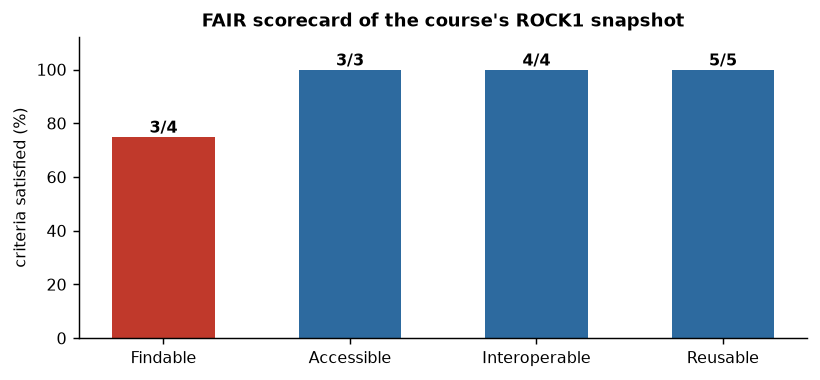

In [18]:
# Figure: the FAIR scorecard, by principle.
fig, ax = plt.subplots(figsize=(6.4, 3.0))
order = ["F", "A", "I", "R"]
heights = [by_letter.loc[k, "score_%"] for k in order]
colours = ["#c0392b" if h < 100 else "#2d6a9f" for h in heights]
ax.bar(order, heights, color=colours, width=0.55)
for i, (k, h) in enumerate(zip(order, heights)):
    ax.text(i, h + 1.5, f"{int(by_letter.loc[k, 'sum'])}/{int(by_letter.loc[k, 'size'])}",
            ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 112); ax.set_ylabel("criteria satisfied (%)")
ax.set_xticks(range(4)); ax.set_xticklabels(["Findable", "Accessible", "Interoperable", "Reusable"])
ax.set_title("FAIR scorecard of the course's ROCK1 snapshot")
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> The same assessment as a scorecard. Accessible, Interoperable and Reusable are fully satisfied because the dataset ships open formats, standard identifiers (InChIKey, ChEMBL and UniProt accessions), a column dictionary, a licence and a step-by-step curation log. Findable is incomplete for one reason only — no persistent identifier — which is a five-minute fix (a Zenodo deposit) and the difference between a file and a citable research object.</p>

<div class="box key"><h4>FAIR for a trained model</h4>
<p>A model is FAIR when: the <em>training set</em> is identified by a DOI and a checksum; the <em>code</em> that trained it is in a tagged, archived repository; the <em>hyperparameters and seed</em> are recorded; the <em>metrics</em> are reported with their validation protocol (which split, how many repetitions); the <em>applicability domain</em> is stated (Unit 17); and the serialised weights carry a licence and a model card (Unit 26). Note that a pickled scikit-learn model is <em>not</em> interoperable — it requires the exact library version to load — which is why this group also stores the training script and the data checksum, never only the binary.</p></div>

## 6. Licences, identifiers and the three files every release carries

Three small files turn a folder into a citable research object, and all three are written once.

- **`LICENSE`** states what others may legally do. For **code**, permissive licences (MIT, BSD-3-Clause, Apache-2.0) allow reuse including in closed software and are the group's default; copyleft licences (GPL) require derived work to carry the same licence. For **data**, CC0 (public domain dedication) and CC BY (attribution) are the standard choices. The decisive constraint for this course: ChEMBL data are distributed under **CC BY-SA 3.0**, a *share-alike* licence, so a table derived from ChEMBL must be redistributed under the same terms — you may not re-licence the course's ROCK1 snapshot as CC0, and a dataset that mixes a share-alike source with an incompatible one cannot be redistributed at all. Check the licence of every source *before* you build a derived table, not after.
- **`CITATION.cff`** is a machine-readable citation file (YAML) that GitHub and Zenodo read to generate the correct citation. It is the software-citation principles<sup class="c"><a href="#r26">[26]</a></sup> made executable.
- **`README.md`** is the human entry point: the question, the layout, the exact commands that reproduce the result, and the data-availability statement. Guidance on documenting scientific software applies in full<sup class="c"><a href="#r27">[27]</a></sup>.

The **persistent identifier** comes from a deposit. Connecting a GitHub repository to Zenodo and creating a release mints a DOI for that exact snapshot of the code, plus a concept DOI that always resolves to the latest version. Data deposits work the same way. A DOI is not a convenience: a repository URL can be renamed or deleted, while a DOI resolves permanently and is what a journal's data-availability statement should contain<sup class="c"><a href="#r28">[28]</a></sup><sup class="c"><a href="#r29">[29]</a></sup>.

In [19]:
# Write the three release files, then parse CITATION.cff back to prove it is machine-readable.
release = SCRATCH / "release"
release.mkdir(exist_ok=True)

(release / "LICENSE").write_text(
    "MIT License\n\nCopyright (c) 2026 Laboratorio de Bioinformatica y Quimica Computacional (LBQC),\n"
    "Universidad Catolica del Maule\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\n"
    "of this software and associated documentation files (the \"Software\"), to deal\nin the Software without restriction...\n",
    encoding="utf-8")

citation = {
    "cff-version": "1.2.0",
    "message": "If you use this dataset or code, please cite the following.",
    "title": "ROCK1 bioactivity snapshot and analysis code (LBQC data-science course)",
    "authors": [{"family-names": "Bustos", "given-names": "Daniel",
                 "affiliation": "Universidad Catolica del Maule", "orcid": "https://orcid.org/0000-0000-0000-0000"}],
    "version": "1.0.0",
    "date-released": "2026-10-18",
    "license": "CC-BY-SA-3.0",
    "type": "dataset",
    "keywords": ["ROCK1", "ChEMBL", "QSAR", "reproducibility"],
    "references": [{"type": "article", "title": "The ChEMBL database in 2023",
                    "doi": "10.1093/nar/gkad1004", "year": 2024,
                    "authors": [{"family-names": "Zdrazil", "given-names": "Barbara"}]}],
}
(release / "CITATION.cff").write_text(yaml.safe_dump(citation, sort_keys=False), encoding="utf-8")

(release / "README.md").write_text(
    "# ROCK1 bioactivity snapshot\n\n## Data availability\n"
    f"ChEMBL release {manifest['chembl_release']}, query `{manifest['query']}`,\n"
    f"downloaded {manifest['download_date']}; SHA-256 of each file in `manifest_rock1.json`.\n"
    f"Licence: {manifest['licence']}.\n\n## Reproduce\n```\nconda env create -f environment.yml\n"
    "python src/build_dataset.py   # rebuilds data/processed from data/raw\n```\n", encoding="utf-8")

parsed = yaml.safe_load((release / "CITATION.cff").read_text(encoding="utf-8"))
print("files written:", sorted(p.name for p in release.iterdir()))
print("\nCITATION.cff parses back to a dict with keys:", sorted(parsed))
print("citation title :", parsed["title"])
print("licence        :", parsed["license"], "| version:", parsed["version"],
      "| released:", parsed["date-released"])
print("cited reference:", parsed["references"][0]["title"], "doi:" + parsed["references"][0]["doi"])
print("\nlicence compatibility check: dataset licence is",
      manifest['licence'], "->", "share-alike: derived tables must keep CC BY-SA"
      if "SA" in manifest["licence"] else "no share-alike obligation")

files written: ['CITATION.cff', 'LICENSE', 'README.md']

CITATION.cff parses back to a dict with keys: ['authors', 'cff-version', 'date-released', 'keywords', 'license', 'message', 'references', 'title', 'type', 'version']
citation title : ROCK1 bioactivity snapshot and analysis code (LBQC data-science course)
licence        : CC-BY-SA-3.0 | version: 1.0.0 | released: 2026-10-18
cited reference: The ChEMBL database in 2023 doi:10.1093/nar/gkad1004

licence compatibility check: dataset licence is CC BY-SA 3.0 (ChEMBL) -> share-alike: derived tables must keep CC BY-SA


The citation file parses back into a dictionary, which is the only test that matters — a `CITATION.cff` with a YAML error is silently ignored by GitHub and by Zenodo. Note the fields that earn their place: a `version` and a `date-released` (so a reader can cite the exact snapshot), a `license` identifier from the SPDX list rather than free text, and a `references` block pointing at the source database's own paper, which is how attribution chains are kept intact.

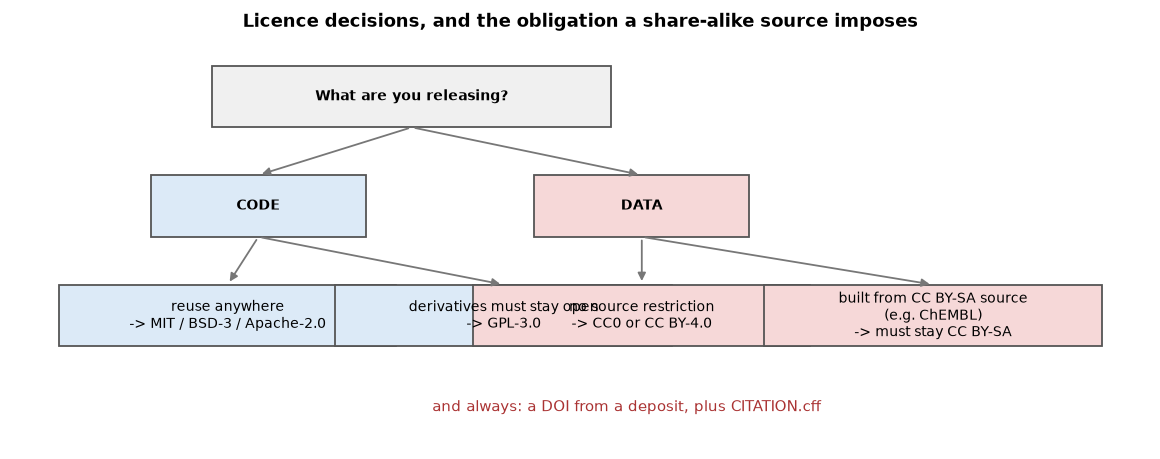

In [20]:
# Conceptual figure: choosing a licence for code and for data.
fig, ax = plt.subplots(figsize=(9.0, 3.6))
boxes = [
    (0.5, 2.6, "What are you releasing?", "#f0f0f0"),
    (0.1, 1.5, "CODE", "#dceaf7"), (2.6, 1.5, "DATA", "#f6d8d8"),
    (-0.5, 0.4, "reuse anywhere\n-> MIT / BSD-3 / Apache-2.0", "#dceaf7"),
    (1.3, 0.4, "derivatives must stay open\n-> GPL-3.0", "#dceaf7"),
    (2.2, 0.4, "no source restriction\n-> CC0 or CC BY-4.0", "#f6d8d8"),
    (4.1, 0.4, "built from CC BY-SA source\n(e.g. ChEMBL)\n-> must stay CC BY-SA", "#f6d8d8"),
]
for x, y, label, colour in boxes:
    w = 2.2 if y == 0.4 else (1.4 if y == 1.5 else 2.6)
    ax.add_patch(plt.Rectangle((x, y), w, 0.62, facecolor=colour, edgecolor="#555555", lw=1.0))
    ax.text(x + w / 2, y + 0.31, label, ha="center", va="center", fontsize=7.6,
            fontweight="bold" if y >= 1.5 else "normal")
for (x0, y0), (x1, y1) in [((1.8, 2.6), (0.8, 2.12)), ((1.8, 2.6), (3.3, 2.12)),
                           ((0.8, 1.5), (0.6, 1.02)), ((0.8, 1.5), (2.4, 1.02)),
                           ((3.3, 1.5), (3.3, 1.02)), ((3.3, 1.5), (5.2, 1.02))]:
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#777777", lw=1.0))
ax.text(3.2, -0.25, "and always: a DOI from a deposit, plus CITATION.cff", ha="center",
        fontsize=8.2, color="#a33")
ax.set_xlim(-0.8, 6.6); ax.set_ylim(-0.6, 3.5); ax.axis("off")
ax.set_title("Licence decisions, and the obligation a share-alike source imposes")
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> The licence decision as this group makes it. The right-hand branch is the one that catches students: a derived table inherits the obligations of its source, so a snapshot built from ChEMBL (CC BY-SA 3.0) must be redistributed under share-alike terms even if your own code is MIT. Code and data are licensed separately and may have different licences in the same repository — the <code>LICENSE</code> file covers the code, and the data licence is stated in the manifest and the README.</p>

## 7. A reproducibility audit

The final exercise of this unit is the one a reviewer performs. We create a project that looks plausible and contains six deliberate, extremely common defects, then audit it with code. Every check below is mechanical: it reads files and answers yes or no, which is what makes it usable as a pre-submission checklist.

In [21]:
# Build a plausible-looking project with six deliberate defects, then audit it.
bad = SCRATCH / "plausible_project"
for d in ["data/raw", "notebooks", "src", "figures"]:
    (bad / d).mkdir(parents=True, exist_ok=True)
(bad / "data/raw/activities.csv").write_text("id,value\n1,25\n", encoding="utf-8")          # data present
(bad / "notebooks/analysis.ipynb").write_text(json.dumps({"cells": [{"cell_type": "code", "source": [
    "df = pd.read_csv('/Users/student/Desktop/final_data_v3_FINAL.csv')\n",
    "X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25)\n",
    "print('R2', model.score(X_te, y_te))\n"]}]}), encoding="utf-8")
(bad / "src" / "model.py").write_text("import numpy as np\ndef fit(X, y):\n"
                                      "    idx = np.random.permutation(len(y))\n    return idx\n", encoding="utf-8")
(bad / "README.md").write_text("# Project\n\nRun the notebook.\n", encoding="utf-8")

def audit(root):
    nb_text = " ".join(p.read_text(encoding="utf-8", errors="replace") for p in root.rglob("*.ipynb"))
    py_text = " ".join(p.read_text(encoding="utf-8", errors="replace") for p in root.rglob("*.py"))
    code_text = nb_text + " " + py_text
    readme = (root / "README.md").read_text(encoding="utf-8") if (root / "README.md").exists() else ""
    return [
        ("environment file present", any((root / f).exists() for f in ["environment.yml", "requirements.txt"])),
        ("data manifest with checksums", any(root.rglob("manifest*.json"))),
        ("data kept out of version control", (root / ".gitignore").exists()),
        ("no absolute path in code", not re.search(r"['\"](/Users/|/home/|C:\\\\)", code_text)),
        ("randomness is seeded", ("random_state" in code_text or "default_rng" in code_text)
                                 and "np.random.permutation" not in code_text),
        ("README states how to reproduce", "conda" in readme or "python src" in readme),
        ("LICENSE present", (root / "LICENSE").exists()),
        ("CITATION.cff present", (root / "CITATION.cff").exists()),
    ]

report = pd.DataFrame(audit(bad), columns=["check", "passes"])
print("audit of the plausible-looking project:")
print(report.to_string(index=False))
print("\npassed %d of %d checks" % (report['passes'].sum(), len(report)))
print("\nthe same audit on the release folder written in Section 6:")
report_good = pd.DataFrame(audit(release), columns=["check", "passes"])
print("passed %d of %d checks" % (report_good['passes'].sum(), len(report_good)))

audit of the plausible-looking project:
                           check  passes
        environment file present   False
    data manifest with checksums   False
data kept out of version control   False
        no absolute path in code   False
            randomness is seeded   False
  README states how to reproduce   False
                 LICENSE present   False
            CITATION.cff present   False

passed 0 of 8 checks

the same audit on the release folder written in Section 6:
passed 4 of 8 checks


The plausible project fails most of the checks, and each failure corresponds to a sentence a reviewer writes. The absolute path `/Users/student/Desktop/final_data_v3_FINAL.csv` means nobody else can run the notebook and nobody knows which of the versions implied by that file name was used. The split without `random_state` and the `np.random.permutation` call inside `src/model.py` mean the reported $R^2$ is one draw from the histogram of Figure 4. The missing environment file means the result cannot be reproduced even with the code. The missing manifest means the data are unidentified. The `README` that says "run the notebook" documents nothing.

Note that the release folder written in Section 6 does not pass everything either — it has a `LICENSE` and a `CITATION.cff` but no environment file or manifest of its own, because it is only a fragment. A real project passes all eight; that is the bar.

<div class="exercise"><h4>Exercise 2</h4>
<p>Fix the plausible project in code: write an <code>environment.yml</code> and a <code>.gitignore</code> into it, build a manifest for <code>data/raw/activities.csv</code> with <code>build_manifest</code>-style logic, rewrite the notebook source to use a relative path and an explicit <code>random_state=0</code>, and re-run <code>audit</code>. How many checks pass now? Then add a ninth check of your own — for example, that every figure in <code>figures/</code> has a script in <code>src/</code> that produces it — and argue in two sentences why that check matters.</p></div>

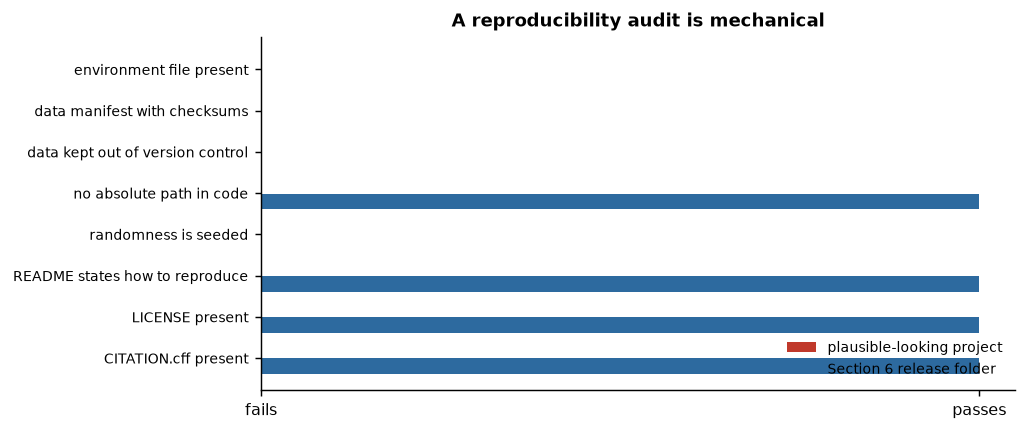

In [22]:
# Figure: the two audits side by side.
fig, ax = plt.subplots(figsize=(8.0, 3.4))
labels = [c for c, _ in audit(bad)]
y = np.arange(len(labels))
ax.barh(y - 0.2, [1 if v else 0 for _, v in audit(bad)], height=0.38,
        color="#c0392b", label="plausible-looking project")
ax.barh(y + 0.2, [1 if v else 0 for _, v in audit(release)], height=0.38,
        color="#2d6a9f", label="Section 6 release folder")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
ax.set_xticks([0, 1]); ax.set_xticklabels(["fails", "passes"])
ax.set_title("A reproducibility audit is mechanical")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.invert_yaxis()
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> The eight audit checks applied to the deliberately defective project (red) and to the release folder of Section 6 (blue). Neither is complete, and that is the teaching point: reproducibility is not a property a project has or lacks in general, but a list of specific, checkable facts, each of which is cheap to fix once it has been named. Run this audit on your own project before your supervisor does.</p>

In [23]:
# Clean up every temporary artefact created by this notebook.
shutil.rmtree(SCRATCH, ignore_errors=True)
print("scratch directory removed:", not SCRATCH.exists())
print("objects in the miniature git store (in memory only):", len(OBJECTS))

scratch directory removed: True
objects in the miniature git store (in memory only): 16


## 8. Summary

You should now be able to explain, without notes:

- The difference between repeatable, reproducible and replicable, and which of the three this unit buys.
- Git's object model: blob, tree, commit, tag; content addressing; a branch as a movable pointer; the history as a DAG.
- How an object identifier is computed, and why one changed byte changes the whole identifier.
- What a merge base is, why most merges are automatic, what a conflict file contains, and how to resolve one.
- Which files must never enter a repository, and where data and secrets go instead.
- The three levels of environment specification, what each is for, and what none of them captures.
- Why an unseeded split makes a reported metric one draw from a distribution — and roughly how wide that distribution was for the model in Section 3.3.
- What a data manifest records, how to verify a file against it, and why hashing a DataFrame is not the same as hashing a file.
- The FAIR principles applied to a dataset and to a trained model, and the one criterion the course dataset currently fails.
- How to choose a licence for code and for data, what a share-alike source obliges you to do, and what `CITATION.cff` and a DOI add.
- The eight mechanical checks of a reproducibility audit.

<div class="box bridge"><h4>Bridge — where this continues</h4>
<p><a href="../U3_Getting_Data/index.html">Unit 3</a> fills <code>data/raw/</code> from APIs, databases and SQL, and every download it makes is the thing this unit's manifest describes; <a href="../U6_Data_Quality/index.html">Unit 6</a> turns the curation protocol documented here into a reproducible, logged pipeline; <a href="../U12_Validation/index.html">Unit 12</a> replaces the single split of Section 3.3 with validation that reports its own dispersion; <a href="../U23_Communication/index.html">Unit 23</a> writes the data-availability statement; <a href="../U24_Software_Engineering/index.html">Unit 24</a> turns <code>src/</code> into a tested package with continuous integration, and <a href="../U25_Scaling_HPC/index.html">Unit 25</a> puts the pinned environment into a container. In the sister courses, the cheminformatics elective applies the same provenance discipline to <a href="../../../Cheminformatics/U6_Databases/index.html">chemical databases</a> and <a href="../../../Cheminformatics/U7_Data_Curation/index.html">curation</a>, BGM324 shows the simulation outputs that need it in <a href="../../../BGM324/05_Molecular_Dynamics/index.html">molecular dynamics</a>, and BGM411 (<a href="../../../BGM411/Python/index.html">study material</a>) uses the same seeding and reporting rules for model code.</p></div>

## 9. Self-assessment

<details><summary>Q1. Two identical files sit in two unrelated repositories on two continents. What can you say about their git object identifiers?</summary>
<p>They are identical, because the identifier is the SHA-1 of <code>"blob " + length + NUL + content</code> — a function of content alone, with no contribution from the file name, path, timestamp or repository. This is what lets git deduplicate storage and verify integrity with the same mechanism.</p></details>

<details><summary>Q2. Why does committing an unchanged file ten times not store ten copies?</summary>
<p>Because each commit stores a tree that <em>points at</em> blob ids. If the content has not changed, the blob id has not changed, so every tree references the same existing object. Only the small tree and commit objects are new. This is why frequent commits are cheap and why "I will commit when it is finished" is bad advice.</p></details>

<details><summary>Q3. A merge produced a conflict in one line of a file and merged forty other changed lines silently. Explain both behaviours in terms of the merge base.</summary>
<p>Git compares each side against the most recent common ancestor. Where only one side differs from the base, that side's version is taken (forty lines). Where both sides differ from the base and from each other, no rule can decide, so the two versions are written into the file between markers for a human to resolve (one line).</p></details>

<details><summary>Q4. Your collaborator asks you to commit a 400 MB trajectory "so we both have it". What do you answer?</summary>
<p>That git stores every version forever and in every clone, so the repository would grow by 400 MB per version for everyone, permanently. The trajectory goes to a data deposit (with a DOI) or an institutional store; the repository carries its checksum, its location and the script that downloads it. If it must be versioned with the code, git-lfs or a data-version-control tool keeps pointers in git and bytes elsewhere.</p></details>

<details><summary>Q5. You pin <code>pandas==2.2.1</code> in <code>requirements.txt</code>. Is your analysis now reproducible?</summary>
<p>More reproducible, not reproducible. The file does not pin the transitive dependencies (Figure 3 showed how many there are), the interpreter build, the BLAS library behind NumPy, the operating system or the hardware. A lock file pins versions and builds for a platform; a container pins the whole user-space software stack. Numerical results can still differ in the last digits across architectures.</p></details>

<details><summary>Q6. A manuscript reports a single test $R^2$ for this descriptor model, with no seed and no repetitions. What is the honest objection, quantitatively?</summary>
<p>That the number is one draw from the distribution of Figure 4: refitting the same model on the same data with only the split changed produced a spread between the unluckiest and luckiest seed that is a large fraction of the value itself. Without repetitions one cannot tell a real improvement from a lucky split. Report a median and a dispersion over repeated, seeded splits.</p></details>

<details><summary>Q7. Why hash a file on disk rather than the DataFrame you loaded from it?</summary>
<p>Because the digest must identify the bytes a collaborator can download. A DataFrame re-serialised with <code>to_csv()</code> depends on float formatting, column order, line endings and the pandas version, so its digest changes when nothing about the data changed — and, worse, two genuinely different files can serialise to the same text after type coercion. Hash the file in binary mode and record rows and columns separately as a readable cross-check.</p></details>

<details><summary>Q8. A dataset has a DOI, a licence and rich metadata, but access requires a signed agreement. Is it FAIR?</summary>
<p>It can be. FAIR requires that the metadata be findable and accessible and that the access conditions be explicit and machine-readable; it does not require the data themselves to be open. "FAIR" and "open" are different axes, and conflating them is a common error in data-management plans.</p></details>

<details><summary>Q9. Your code is MIT-licensed and your derived table was built from ChEMBL. May you release the table as CC0?</summary>
<p>No. ChEMBL is distributed under CC BY-SA 3.0, a share-alike licence, so a derived table must be redistributed under the same terms; the MIT licence on your code is unaffected and the two coexist in one repository. Check source licences before building a derived table, especially before combining sources whose licences may be incompatible.</p></details>

<details><summary>Q10. What does a Zenodo DOI add that a GitHub URL does not?</summary>
<p>Permanence and specificity. A repository can be renamed, made private or deleted, and its URL then resolves to nothing; a DOI resolves permanently to an archived snapshot. A Zenodo release also mints a version DOI (this exact snapshot) alongside a concept DOI (always the latest), which is what a data-availability statement and a <code>CITATION.cff</code> should carry.</p></details>

<details><summary>Q11. Name the six defects in the "plausible project" of Section 7 and the single sentence each would attract from a reviewer.</summary>
<p>Absolute path (nobody else can run it); unseeded split and <code>np.random.permutation</code> (the metric is one draw); no environment file (the software is unrecorded); no data manifest (the data are unidentified); data committed with no <code>.gitignore</code> (the repository will bloat and the data are still unverified); a README that says "run the notebook" (no reproduction instructions). Missing LICENSE and CITATION.cff complete the list: no legal basis for reuse and no citation.</p></details>

<details><summary>Q12. Why does this unit compute git's hashes instead of simply teaching the commands?</summary>
<p>Because the commands are unmemorable until the model is clear, and because the model explains their behaviour: why identifiers are long hexadecimal strings, why commits are cheap, why history is a graph, why a conflict is a refusal rather than a failure, and why <code>--force</code> is dangerous. Once content addressing is understood, the command list in Section 2.4 reads as a description of simple graph operations.</p></details>

## Glossary

<dl class="gloss">
<dt>Avalanche effect</dt><dd>The property that flipping one input bit changes about half the output bits of a hash function.</dd>
<dt>Blob / tree / commit</dt><dd>Git's object types: file contents, a directory listing, and a snapshot with parents, author and message.</dd>
<dt>Branch</dt><dd>A movable pointer to a commit; creating one is nearly free.</dd>
<dt>CITATION.cff</dt><dd>A machine-readable YAML citation file read by GitHub and Zenodo.</dd>
<dt>Content addressing</dt><dd>Naming an object by the hash of its contents, so the name proves the contents.</dd>
<dt>DAG</dt><dd>Directed acyclic graph; the shape of a git history, in which a merge commit has two parents.</dd>
<dt>DOI</dt><dd>Digital object identifier; a permanently resolvable name for a deposited snapshot.</dd>
<dt>FAIR</dt><dd>Findable, Accessible, Interoperable, Reusable — principles for research outputs; not a synonym for open.</dd>
<dt>Lock file</dt><dd>A platform-specific record of exact versions, builds and hashes, from which an installation is reproducible.</dd>
<dt>Manifest</dt><dd>A text record of each data file's source, query, date, licence and checksum.</dd>
<dt>Merge base</dt><dd>The most recent common ancestor of two branches; the reference against which both sides are compared.</dd>
<dt>Merge conflict</dt><dd>Git's refusal to choose between two edits of the same region; resolved by a human, not an error.</dd>
<dt>Provenance</dt><dd>The documented chain from an original source to the file in front of you.</dd>
<dt>Pull request</dt><dd>A request to merge a branch, carrying review and discussion; the unit of collaboration on GitHub.</dd>
<dt>SHA-1 / SHA-256</dt><dd>Cryptographic hash functions producing 160-bit and 256-bit digests; git names objects with the former, integrity records use the latter.</dd>
<dt>Share-alike</dt><dd>A licence condition (as in CC BY-SA) requiring derived works to carry the same licence.</dd>
<dt>Staging area</dt><dd>The set of blobs that <code>git commit</code> will turn into the next tree.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Eglen SJ, Marwick B, Halchenko YO, et al. Toward standard practices for sharing computer code and programs in neuroscience. <em>Nat Neurosci</em>. 2017;20(6):770-773. <a href="https://doi.org/10.1038/nn.4550">doi:10.1038/nn.4550</a></li>
<li id="r2">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r3">Mendez D, Gaulton A, Bento AP, et al. ChEMBL: towards direct deposition of bioassay data. <em>Nucleic Acids Res</em>. 2019;47(D1):D930-D940. <a href="https://doi.org/10.1093/nar/gky1075">doi:10.1093/nar/gky1075</a></li>
<li id="r4">Walters WP. Modeling, informatics, and the quest for reproducibility. <em>J Chem Inf Model</em>. 2013;53(7):1529-1530. <a href="https://doi.org/10.1021/ci400197w">doi:10.1021/ci400197w</a></li>
<li id="r5">Baker M. 1,500 scientists lift the lid on reproducibility. <em>Nature</em>. 2016;533(7604):452-454. <a href="https://doi.org/10.1038/533452a">doi:10.1038/533452a</a></li>
<li id="r6">Stodden V, Seiler J, Ma Z. An empirical analysis of journal policy effectiveness for computational reproducibility. <em>Proc Natl Acad Sci USA</em>. 2018;115(11):2584-2589. <a href="https://doi.org/10.1073/pnas.1708290115">doi:10.1073/pnas.1708290115</a></li>
<li id="r7">Hutson M. Artificial intelligence faces reproducibility crisis. <em>Science</em>. 2018;359(6377):725-726. <a href="https://doi.org/10.1126/science.359.6377.725">doi:10.1126/science.359.6377.725</a></li>
<li id="r8">Gundersen OE, Kjensmo S. State of the art: reproducibility in artificial intelligence. <em>Proc AAAI Conf Artif Intell</em>. 2018;32(1):1644-1651. <a href="https://doi.org/10.1609/aaai.v32i1.11503">doi:10.1609/aaai.v32i1.11503</a></li>
<li id="r9">Haibe-Kains B, Adam GA, Hosny A, et al. Transparency and reproducibility in artificial intelligence. <em>Nature</em>. 2020;586(7829):E14-E16. <a href="https://doi.org/10.1038/s41586-020-2766-y">doi:10.1038/s41586-020-2766-y</a></li>
<li id="r10">Sandve GK, Nekrutenko A, Taylor J, Hovig E. Ten simple rules for reproducible computational research. <em>PLoS Comput Biol</em>. 2013;9(10):e1003285. <a href="https://doi.org/10.1371/journal.pcbi.1003285">doi:10.1371/journal.pcbi.1003285</a></li>
<li id="r11">Heil BJ, Hoffman MM, Markowetz F, Lee SI, Greene CS, Hicks SC. Reproducibility standards for machine learning in the life sciences. <em>Nat Methods</em>. 2021;18(10):1132-1135. <a href="https://doi.org/10.1038/s41592-021-01256-7">doi:10.1038/s41592-021-01256-7</a></li>
<li id="r12">Wilson G, Bryan J, Cranston K, Kitzes J, Nederbragt L, Teal TK. Good enough practices in scientific computing. <em>PLoS Comput Biol</em>. 2017;13(6):e1005510. <a href="https://doi.org/10.1371/journal.pcbi.1005510">doi:10.1371/journal.pcbi.1005510</a></li>
<li id="r13">Peng RD. Reproducible research in computational science. <em>Science</em>. 2011;334(6060):1226-1227. <a href="https://doi.org/10.1126/science.1213847">doi:10.1126/science.1213847</a></li>
<li id="r14">Perez-Riverol Y, Gatto L, Wang R, et al. Ten simple rules for taking advantage of git and GitHub. <em>PLoS Comput Biol</em>. 2016;12(7):e1004947. <a href="https://doi.org/10.1371/journal.pcbi.1004947">doi:10.1371/journal.pcbi.1004947</a></li>
<li id="r15">Blischak JD, Davenport ER, Wilson G. A quick introduction to version control with Git and GitHub. <em>PLoS Comput Biol</em>. 2016;12(1):e1004668. <a href="https://doi.org/10.1371/journal.pcbi.1004668">doi:10.1371/journal.pcbi.1004668</a></li>
<li id="r16">Ram K. Git can facilitate greater reproducibility and increased transparency in science. <em>Source Code Biol Med</em>. 2013;8(1):7. <a href="https://doi.org/10.1186/1751-0473-8-7">doi:10.1186/1751-0473-8-7</a></li>
<li id="r17">Boettiger C. An introduction to Docker for reproducible research. <em>ACM SIGOPS Oper Syst Rev</em>. 2015;49(1):71-79. <a href="https://doi.org/10.1145/2723872.2723882">doi:10.1145/2723872.2723882</a></li>
<li id="r18">Grüning B, Chilton J, Köster J, et al. Practical computational reproducibility in the life sciences. <em>Cell Syst</em>. 2018;6(6):631-635. <a href="https://doi.org/10.1016/j.cels.2018.03.014">doi:10.1016/j.cels.2018.03.014</a></li>
<li id="r19">Nüst D, Sochat V, Marwick B, et al. Ten simple rules for writing Dockerfiles for reproducible data science. <em>PLoS Comput Biol</em>. 2020;16(11):e1008316. <a href="https://doi.org/10.1371/journal.pcbi.1008316">doi:10.1371/journal.pcbi.1008316</a></li>
<li id="r20">Artrith N, Butler KT, Coudert FX, et al. Best practices in machine learning for chemistry. <em>Nat Chem</em>. 2021;13(6):505-508. <a href="https://doi.org/10.1038/s41557-021-00716-z">doi:10.1038/s41557-021-00716-z</a></li>
<li id="r21">Wilkinson MD, Dumontier M, Aalbersberg IJ, et al. The FAIR guiding principles for scientific data management and stewardship. <em>Sci Data</em>. 2016;3:160018. <a href="https://doi.org/10.1038/sdata.2016.18">doi:10.1038/sdata.2016.18</a></li>
<li id="r22">Mons B, Neylon C, Velterop J, Dumontier M, da Silva Santos LOB, Wilkinson MD. Cloudy, increasingly FAIR; revisiting the FAIR data guiding principles for the European Open Science Cloud. <em>Inf Serv Use</em>. 2017;37(1):49-56. <a href="https://doi.org/10.3233/ISU-170824">doi:10.3233/ISU-170824</a></li>
<li id="r23">Jacobsen A, de Miranda Azevedo R, Juty N, et al. FAIR principles: interpretations and implementation considerations. <em>Data Intell</em>. 2020;2(1-2):10-29. <a href="https://doi.org/10.1162/dint_r_00024">doi:10.1162/dint_r_00024</a></li>
<li id="r24">Lamprecht AL, Garcia L, Kuzak M, et al. Towards FAIR principles for research software. <em>Data Sci</em>. 2019;3(1):37-59. <a href="https://doi.org/10.3233/DS-190026">doi:10.3233/DS-190026</a></li>
<li id="r25">Barker M, Chue Hong NP, Katz DS, et al. Introducing the FAIR principles for research software. <em>Sci Data</em>. 2022;9(1):622. <a href="https://doi.org/10.1038/s41597-022-01710-x">doi:10.1038/s41597-022-01710-x</a></li>
<li id="r26">Smith AM, Katz DS, Niemeyer KE. Software citation principles. <em>PeerJ Comput Sci</em>. 2016;2:e86. <a href="https://doi.org/10.7717/peerj-cs.86">doi:10.7717/peerj-cs.86</a></li>
<li id="r27">Lee BD. Ten simple rules for documenting scientific software. <em>PLoS Comput Biol</em>. 2018;14(12):e1006561. <a href="https://doi.org/10.1371/journal.pcbi.1006561">doi:10.1371/journal.pcbi.1006561</a></li>
<li id="r28">Nosek BA, Alter G, Banks GC, et al. Promoting an open research culture. <em>Science</em>. 2015;348(6242):1422-1425. <a href="https://doi.org/10.1126/science.aab2374">doi:10.1126/science.aab2374</a></li>
<li id="r29">Chen X, Dallmeier-Tiessen S, Dasler R, et al. Open is not enough. <em>Nat Phys</em>. 2018;15(2):113-119. <a href="https://doi.org/10.1038/s41567-018-0342-2">doi:10.1038/s41567-018-0342-2</a></li>
<li id="r30">Munafò MR, Nosek BA, Bishop DVM, et al. A manifesto for reproducible science. <em>Nat Hum Behav</em>. 2017;1:0021. <a href="https://doi.org/10.1038/s41562-016-0021">doi:10.1038/s41562-016-0021</a></li>
<li id="r31">Kapoor S, Narayanan A. Leakage and the reproducibility crisis in machine-learning-based science. <em>Patterns</em>. 2023;4(9):100804. <a href="https://doi.org/10.1016/j.patter.2023.100804">doi:10.1016/j.patter.2023.100804</a></li>
<li id="r32">Wilson G, Aruliah DA, Brown CT, et al. Best practices for scientific computing. <em>PLoS Biol</em>. 2014;12(1):e1001745. <a href="https://doi.org/10.1371/journal.pbio.1001745">doi:10.1371/journal.pbio.1001745</a></li>
<li id="r33">Community TTW. The Turing Way: a handbook for reproducible, ethical and collaborative research. <em>Zenodo</em>. 2022. <a href="https://doi.org/10.5281/zenodo.3233853">doi:10.5281/zenodo.3233853</a></li>
<li id="r34">Papadatos G, Gaulton A, Hersey A, Overington JP. Activity, assay and target data curation and quality in the ChEMBL database. <em>J Comput Aided Mol Des</em>. 2015;29(9):885-896. <a href="https://doi.org/10.1007/s10822-015-9860-5">doi:10.1007/s10822-015-9860-5</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Chacon S, Straub B. <em>Pro Git</em>. 2nd ed. Apress; 2014. (Free online; chapters 1–3 and 10 — "Git Internals" — are the companion reading for Section 2.)</li>
<li>VanderPlas J. <em>Python Data Science Handbook</em>. 2nd ed. O'Reilly; 2022.</li>
<li>Wilson G et al. <em>Research Software Engineering with Python</em>. CRC Press; 2021.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li><a href="https://book.the-turing-way.org/">The Turing Way</a> — "Guide for reproducible research", the most complete free treatment of this unit's material.</li>
<li><a href="https://software-carpentry.org/lessons/">Software Carpentry</a> — the "Version Control with Git" lesson, two hours, hands-on.</li>
<li><a href="https://citation-file-format.github.io/">Citation File Format</a> — the <code>CITATION.cff</code> schema and an online generator.</li>
<li><a href="https://choosealicense.com/">choosealicense.com</a> and <a href="https://spdx.org/licenses/">SPDX licence list</a> — licence texts and identifiers.</li>
<li><a href="https://zenodo.org/">Zenodo</a> — DOI minting for GitHub releases and datasets; see its GitHub integration documentation.</li>
</ul>